# Softmax and cross-entropy

**AI 4200, Week 7.2.** This notebook reproduces the numbers and figures on the lecture board *Softmax & Cross-Entropy*:
the softmax of the board's ten logits, the softmax Jacobian and what it costs, the shared-sum trick for the backward pass,
the step from BCE to cross-entropy, and `nn.CrossEntropyLoss` in PyTorch.

**To run it** you need numpy, matplotlib and PyTorch (all preinstalled on Colab). The first code cell downloads about
5 MB of MNIST digits, used only for the pictures. Everything runs on a CPU in a few seconds.

All numbers are computed here from the board's logits, except the four probabilities in the cross-entropy example
(0.81, 0.93, 0.97, 0.64), which are illustrative values chosen for the slide.

**Notation.** ŷ are logits (one row of Ŷ per example), p̂ = softmax(ŷ) are predicted probabilities, p is the one-hot
true label, ∂P̂/∂Ŷ is the softmax Jacobian and ∂L/∂P̂ is the gradient arriving from the loss.

In [1]:
import io
import json
import os
import tarfile
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.set_printoptions(precision=4, suppress=True)

# Slide colours
BLUE = "#2557D6"
ORANGE = "#C2510F"
INK = "#16181D"
GREY = "#8E94A0"

# The board's running example: logits for one image of a "7"
y_hat = np.array([-1.2, 0.3, 1.1, 0.8, -0.5, -0.9, -2.0, 4.1, 0.2, 1.6])
TRUE_CLASS = 7
p = np.eye(10)[TRUE_CLASS]          # one-hot true label


def softmax(y_hat):
    """Softmax of a vector of logits (subtracting the max avoids overflow and does not change the result)."""
    exps = np.exp(y_hat - y_hat.max())
    return exps / exps.sum()


# MNIST digits from the npm package `mnist` 1.1.0 (a 10,000-digit subset of MNIST stored as JSON)
MNIST_URL = "https://registry.npmjs.org/mnist/-/mnist-1.1.0.tgz"
DIGITS_DIR = os.path.join("mnist_npm", "package", "src", "digits")


def download_mnist_digits():
    """Download and unpack the digit JSON files once; later runs reuse them."""
    if os.path.exists(os.path.join(DIGITS_DIR, "9.json")):
        return
    with urllib.request.urlopen(MNIST_URL) as response:
        archive = tarfile.open(fileobj=io.BytesIO(response.read()), mode="r:gz")
    members = [m for m in archive.getmembers() if m.name.startswith("package/src/digits/")]
    archive.extractall("mnist_npm", members=members, filter="data")


def load_digit(label):
    """Return the first image of the given digit class as a 28 x 28 array with values in [0, 1]."""
    with open(os.path.join(DIGITS_DIR, f"{label}.json")) as f:
        images = np.asarray(json.load(f)["data"], dtype=np.float32).reshape(-1, 28, 28)
    return images[0]


download_mnist_digits()

## 1. Multi-class classification

A network maps a 28 × 28 image (784 pixels) to ten logits ŷ, one per digit. The bar chart is the board's example.
Notice that the logits can be negative and do not sum to 1, so they are not yet probabilities.

logits sum to 3.5


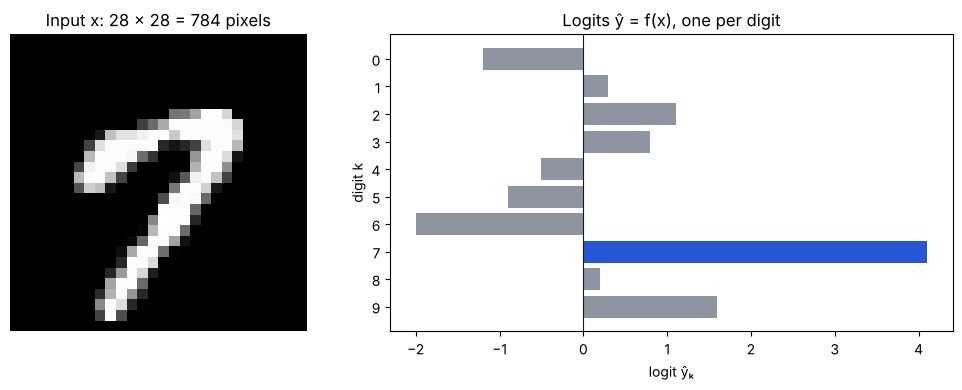

In [2]:
seven = load_digit(7)
print("logits sum to", y_hat.sum())

fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 4), gridspec_kw={"width_ratios": [1, 1.6]})
ax_img.imshow(seven, cmap="gray")
ax_img.set_title("Input x: 28 × 28 = 784 pixels")
ax_img.set_axis_off()

bar_colors = [BLUE if k == TRUE_CLASS else GREY for k in range(10)]
ax_bar.barh(range(10), y_hat, color=bar_colors)
ax_bar.axvline(0, color=INK, linewidth=0.8)
ax_bar.set_yticks(range(10))
ax_bar.invert_yaxis()
ax_bar.set_xlabel("logit ŷₖ")
ax_bar.set_ylabel("digit k")
ax_bar.set_title("Logits ŷ = f(x), one per digit")
plt.tight_layout()
plt.show()

## 2. Softmax forward pass

p̂ᵢ = e^ŷᵢ / Σₖ e^ŷₖ. Every logit is exponentiated, and all ten share one sum in the denominator.
The cell prints the values shown on the slide (classes 0, 7 and 9) and checks that p̂ is a probability vector.

**Slide difference:** the slide prints p̂₇ = 0.810; the exact value is 0.80946, which rounds to 0.809.

In [3]:
exps = np.exp(y_hat)
shared_sum = exps.sum()
p_hat = exps / shared_sum

for k in (0, 7, 9):
    print(f"e^ŷ{k} = {exps[k]:8.4f}    p̂{k} = {p_hat[k]:.5f}")
print(f"Σ e^ŷk = {shared_sum:.4f}")
print("all p̂ > 0:", bool(np.all(p_hat > 0)), "   Σ p̂ =", p_hat.sum())
print("p̂ =", p_hat)

e^ŷ0 =   0.3012    p̂0 = 0.00404
e^ŷ7 =  60.3403    p̂7 = 0.80946
e^ŷ9 =   4.9530    p̂9 = 0.06644
Σ e^ŷk = 74.5439
all p̂ > 0: True    Σ p̂ = 1.0
p̂ = [0.004  0.0181 0.0403 0.0299 0.0081 0.0055 0.0018 0.8095 0.0164 0.0664]


## 3. Backprop needs the Jacobian

Going backward through softmax, ∂L/∂Ŷ = ∂L/∂P̂ · ∂P̂/∂Ŷ: a row vector times an n × n Jacobian for each example.
The slide has no upstream numbers, so the cell uses a random ∂L/∂P̂ just to show the shapes, and checks the sigmoid
comparison: its Jacobian is diagonal, so the product is an element-wise multiply.

In [4]:
def softmax_jacobian(p_hat):
    """∂P̂/∂Ŷ for one example: diag(p̂) − p̂ p̂ᵀ, entry (i, j) = ∂p̂ᵢ/∂ŷⱼ."""
    return np.diag(p_hat) - np.outer(p_hat, p_hat)


rng = np.random.default_rng(0)
dL_dp_hat = rng.normal(size=(1, 10))            # 1 example × 10 classes, arbitrary values
dL_dy_hat = dL_dp_hat @ softmax_jacobian(p_hat)
print("∂L/∂P̂", dL_dp_hat.shape, "· ∂P̂/∂Ŷ", softmax_jacobian(p_hat).shape, "→ ∂L/∂Ŷ", dL_dy_hat.shape)

# Sigmoid: ∂P̂/∂Ŷ = diag(p̂(1 − p̂)), so the matrix product equals an element-wise product
p_hat_sigmoid = 1 / (1 + np.exp(-y_hat))
sigmoid_slope = p_hat_sigmoid * (1 - p_hat_sigmoid)
via_matrix = dL_dp_hat @ np.diag(sigmoid_slope)
via_elementwise = dL_dp_hat * sigmoid_slope
print("sigmoid: matrix product == element-wise product:", np.allclose(via_matrix, via_elementwise))

∂L/∂P̂ (1, 10) · ∂P̂/∂Ŷ (10, 10) → ∂L/∂Ŷ (1, 10)
sigmoid: matrix product == element-wise product: True


## 4. Building the Jacobian costs O(n²)

Entry (i, j) of each heatmap is ∂p̂ᵢ/∂ŷⱼ = p̂ᵢ(δᵢⱼ − p̂ⱼ) for the board's logits. Sigmoid has only the n diagonal
entries; softmax fills all n² cells (blue positive, orange negative, white zero). The colour scale is stretched near
zero so the small off-diagonal entries stay visible. The table below counts entries per example for larger n.

nonzero entries   sigmoid: 10   softmax: 100
softmax diagonal p̂ᵢ(1 − p̂ᵢ): [0.004  0.0178 0.0387 0.029  0.0081 0.0054 0.0018 0.1542 0.0161 0.062 ]
largest |entry|   softmax: 0.1542 (at p̂7)   sigmoid: 0.2475


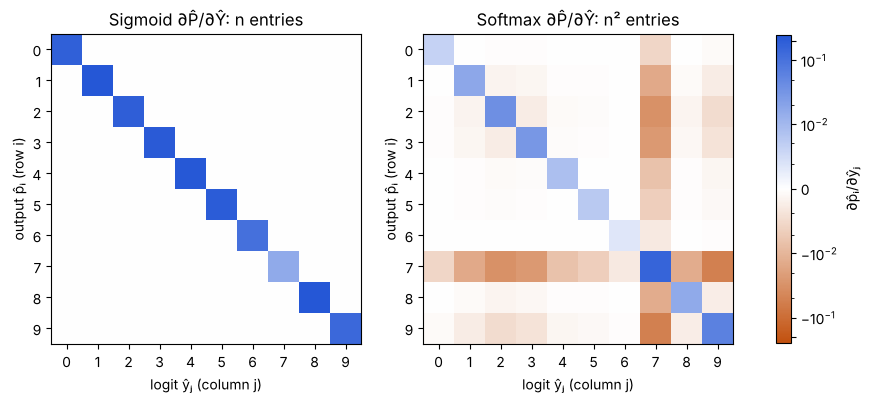

In [5]:
softmax_J = softmax_jacobian(p_hat)
sigmoid_J = np.diag(sigmoid_slope)

print("nonzero entries   sigmoid:", np.count_nonzero(sigmoid_J), "  softmax:", np.count_nonzero(softmax_J))
print("softmax diagonal p̂ᵢ(1 − p̂ᵢ):", np.diag(softmax_J))
print(f"largest |entry|   softmax: {np.abs(softmax_J).max():.4f} (at p̂7)   sigmoid: {np.abs(sigmoid_J).max():.4f}")

# Orange for negative, white for zero, blue for positive; asinh scaling keeps tiny entries visible
orange_white_blue = colors.LinearSegmentedColormap.from_list("orange_white_blue", [ORANGE, "white", BLUE])
limit = max(np.abs(softmax_J).max(), np.abs(sigmoid_J).max())
norm = colors.AsinhNorm(linear_width=0.002, vmin=-limit, vmax=limit)

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, J, title in [(axes[0], sigmoid_J, "Sigmoid ∂P̂/∂Ŷ: n entries"),
                     (axes[1], softmax_J, "Softmax ∂P̂/∂Ŷ: n² entries")]:
    image = ax.imshow(J, cmap=orange_white_blue, norm=norm)
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xlabel("logit ŷⱼ (column j)")
    ax.set_ylabel("output p̂ᵢ (row i)")
    ax.set_title(title)
colorbar = fig.colorbar(image, ax=axes, label="∂p̂ᵢ/∂ŷⱼ", shrink=0.8)
colorbar.set_ticks([-0.2, -0.1, -0.01, 0, 0.01, 0.1, 0.2])
plt.show()

In [6]:
print(f"{'task':<12}{'classes n':>10}{'entries n²':>18}")
for task, n_classes in [("MNIST", 10), ("ImageNet", 1_000), ("50k vocab", 50_000)]:
    print(f"{task:<12}{n_classes:>10,}{n_classes ** 2:>18,}")

task         classes n        entries n²
MNIST               10               100
ImageNet         1,000         1,000,000
50k vocab       50,000     2,500,000,000


## 5. The product is cheaper than the matrix (shared-sum trick)

Because ∂P̂/∂Ŷ = diag(p̂) − p̂p̂ᵀ, every entry of the product contains the same sum s = Σᵢ p̂ᵢ ∂L/∂p̂ᵢ.
Computing s once gives ∂L/∂ŷⱼ = p̂ⱼ(∂L/∂p̂ⱼ − s) in O(n), with no n × n matrix. The cell checks this against
the full Jacobian product with a random ∂L/∂P̂, for n = 3 (as drawn on the slide) and for the board's n = 10.

In [7]:
def shared_sum_backward(p_hat, dL_dp_hat):
    """∂L/∂Ŷ through softmax in O(n): p̂ⱼ (∂L/∂p̂ⱼ − s) with s = Σᵢ p̂ᵢ ∂L/∂p̂ᵢ."""
    s = np.sum(p_hat * dL_dp_hat)
    return p_hat * (dL_dp_hat - s)


rng = np.random.default_rng(1)
for n, p_hat_n in [(3, softmax(y_hat[:3])), (10, p_hat)]:
    dL_dp_hat_n = rng.normal(size=n)
    full_product = dL_dp_hat_n @ softmax_jacobian(p_hat_n)    # O(n²)
    trick = shared_sum_backward(p_hat_n, dL_dp_hat_n)         # O(n)
    print(f"n = {n:>2}: full Jacobian product vs shared sum, max difference = {np.abs(full_product - trick).max():.2e}")

n =  3: full Jacobian product vs shared sum, max difference = 1.39e-17
n = 10: full Jacobian product vs shared sum, max difference = 6.94e-18


## 6. From BCE to cross-entropy

Binary classification has one sigmoid output: Pr(label) = p̂ᵖ(1 − p̂)¹⁻ᵖ and BCE = −log Pr(label).
Multi-class has one softmax output per class: Pr(label) = Πₖ p̂ₖ^pₖ, which with a one-hot p is just p̂ of the true class,
so CE = −Σₖ pₖ log p̂ₖ = −log p̂_true. The bar chart is p̂ from Section 2.

p̂ = 0.8, label 1:  BCE = 0.2231   −log Pr(label) = 0.2231
p̂ = 0.8, label 0:  BCE = 1.6094   −log Pr(label) = 1.6094
Πₖ p̂ₖ^pₖ = 0.8094595632923516   p̂7 = 0.8094595632923516
CE = −Σ pₖ log p̂ₖ = 0.21138845980841678   −log p̂7 = 0.21138845980841678


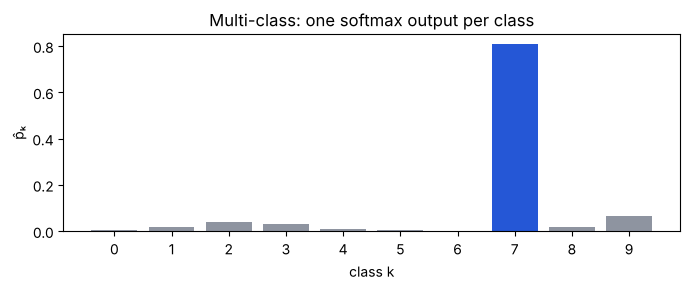

In [8]:
def binary_cross_entropy(p_hat, p):
    """BCE for one sigmoid output p̂ and a 0/1 label p."""
    return -(p * np.log(p_hat) + (1 - p) * np.log(1 - p_hat))


def cross_entropy(p_hat, p):
    """Cross-entropy H(p, p̂) = −Σₖ pₖ log p̂ₖ for one example."""
    return -np.sum(p * np.log(p_hat))


# Binary: BCE is −log of the probability given to the observed label
for label in (1, 0):
    pr_label = 0.8 ** label * (1 - 0.8) ** (1 - label)
    print(f"p̂ = 0.8, label {label}:  BCE = {binary_cross_entropy(0.8, label):.4f}   −log Pr(label) = {-np.log(pr_label):.4f}")

# Multi-class: the product over classes keeps only the true class
print("Πₖ p̂ₖ^pₖ =", np.prod(p_hat ** p), "  p̂7 =", p_hat[TRUE_CLASS])
print("CE = −Σ pₖ log p̂ₖ =", cross_entropy(p_hat, p), "  −log p̂7 =", -np.log(p_hat[TRUE_CLASS]))

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(10), p_hat, color=bar_colors)
ax.set_xticks(range(10))
ax.set_xlabel("class k")
ax.set_ylabel("p̂ₖ")
ax.set_title("Multi-class: one softmax output per class")
plt.tight_layout()
plt.show()

## 7. Cross-entropy loss

For a dataset, the likelihood is the product of the probabilities the model gives each correct label. Taking −log turns
the product into a sum, and averaging over the N examples gives the loss L. The four probabilities are illustrative
values from the slide (0.81 is the board's p̂₇ rounded to 2 dp).

label 7:  p̂_true = 0.81   −log p̂_true = 0.2107
label 2:  p̂_true = 0.93   −log p̂_true = 0.0726
label 1:  p̂_true = 0.97   −log p̂_true = 0.0305
label 0:  p̂_true = 0.64   −log p̂_true = 0.4463
Pr = Π p̂ᵢ,true = 0.4676
−log Pr = Σ −log p̂ᵢ,true = 0.7600   (same as −log of the product: 0.7600)
L = mean over N = 4: 0.1900


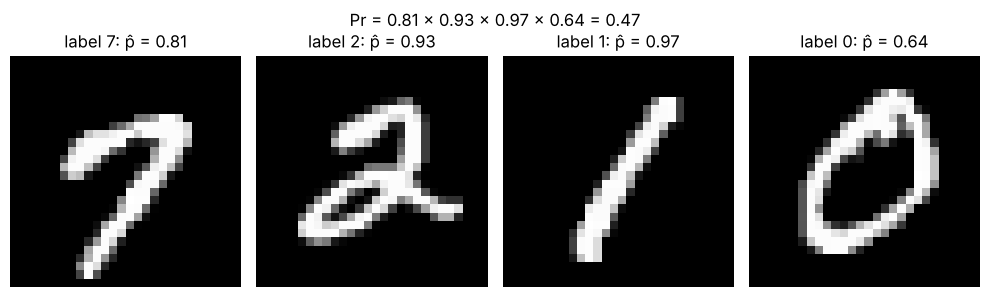

In [9]:
labels = [7, 2, 1, 0]
p_hat_true = np.array([0.81, 0.93, 0.97, 0.64])     # illustrative p̂ of the correct label for each image

likelihood = np.prod(p_hat_true)
neg_log = -np.log(p_hat_true)
loss = neg_log.mean()

for label, prob, nll in zip(labels, p_hat_true, neg_log):
    print(f"label {label}:  p̂_true = {prob:.2f}   −log p̂_true = {nll:.4f}")
print(f"Pr = Π p̂ᵢ,true = {likelihood:.4f}")
print(f"−log Pr = Σ −log p̂ᵢ,true = {neg_log.sum():.4f}   (same as −log of the product: {-np.log(likelihood):.4f})")
print(f"L = mean over N = 4: {loss:.4f}")

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for ax, label, prob in zip(axes, labels, p_hat_true):
    ax.imshow(load_digit(label), cmap="gray")
    ax.set_title(f"label {label}: p̂ = {prob:.2f}")
    ax.set_axis_off()
fig.suptitle(f"Pr = 0.81 × 0.93 × 0.97 × 0.64 = {likelihood:.2f}")
plt.tight_layout()
plt.show()

## 8. CrossEntropyLoss takes logits

With ∂L/∂p̂ⱼ = −pⱼ/p̂ⱼ, the shared sum is s = −Σ pᵢ = −1, so the shared-sum rule gives ∂L/∂Ŷ = P̂ − P and the
Jacobian disappears. The first cell checks this in numpy, both with the shared-sum rule and with the full Jacobian.

s = -1.0
∂L/∂Ŷ = P̂ − P = [ 0.004   0.0181  0.0403  0.0299  0.0081  0.0055  0.0018 -0.1905  0.0164
  0.0664]
shared sum == P̂ − P: True
full Jacobian == P̂ − P: True


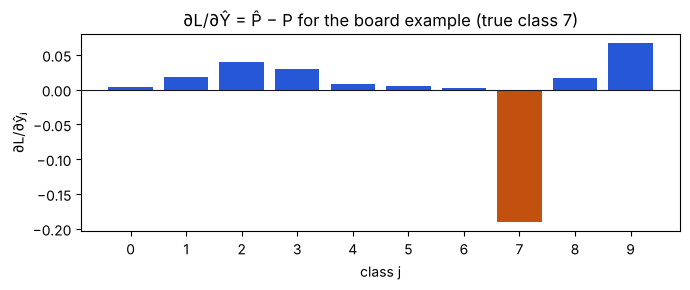

In [10]:
dL_dp_hat = -p / p_hat
s = np.sum(p_hat * dL_dp_hat)
grad_shared_sum = shared_sum_backward(p_hat, dL_dp_hat)
grad_full_jacobian = dL_dp_hat @ softmax_jacobian(p_hat)

print("s =", s)
print("∂L/∂Ŷ = P̂ − P =", p_hat - p)
print("shared sum == P̂ − P:", np.allclose(grad_shared_sum, p_hat - p))
print("full Jacobian == P̂ − P:", np.allclose(grad_full_jacobian, p_hat - p))

gradient = p_hat - p
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(range(10), gradient, color=[BLUE if g > 0 else ORANGE for g in gradient])
ax.axhline(0, color=INK, linewidth=0.8)
ax.set_xticks(range(10))
ax.set_xlabel("class j")
ax.set_ylabel("∂L/∂ŷⱼ")
ax.set_title("∂L/∂Ŷ = P̂ − P for the board example (true class 7)")
plt.tight_layout()
plt.show()

`nn.CrossEntropyLoss` does log-softmax and the negative log-likelihood in one step, from the logits, using
log p̂ⱼ = ŷⱼ − logsumexp(ŷ). On the board's logits it gives −log p̂₇, and autograd's gradient at the logits is P̂ − P.

In [11]:
import torch
import torch.nn as nn

loss_fn = nn.CrossEntropyLoss()
logits = torch.tensor(y_hat, dtype=torch.float64).reshape(1, 10).requires_grad_()
target = torch.tensor([TRUE_CLASS])

loss = loss_fn(logits, target)
loss.backward()
print("CrossEntropyLoss(logits) =", loss.item(), "   −log p̂7 (numpy) =", -np.log(p_hat[TRUE_CLASS]))
print("autograd ∂L/∂Ŷ =", logits.grad.numpy().ravel())
print("equals P̂ − P:", np.allclose(logits.grad.numpy().ravel(), p_hat - p))

CrossEntropyLoss(logits) = 0.2113884598084168    −log p̂7 (numpy) = 0.21138845980841678
autograd ∂L/∂Ŷ = [ 0.004   0.0181  0.0403  0.0299  0.0081  0.0055  0.0018 -0.1905  0.0164
  0.0664]
equals P̂ − P: True


Why not put softmax in the model and take the log afterwards? When the true class gets a very small probability,
softmax underflows to 0 in float32 and log(0) = −inf; the usual clamp hides that but gives the wrong loss.
Here the logits are scaled by 30 and the true label is 0, a class the model is very sure is wrong.

In [12]:
big_logits = torch.tensor(y_hat * 30, dtype=torch.float32).reshape(1, 10)
wrong_label = torch.tensor([0])

p_hat_big = torch.softmax(big_logits, dim=1)
print("p̂0 after softmax (float32):", p_hat_big[0, 0].item())
print("NLL of log(softmax):          ", nn.NLLLoss()(torch.log(p_hat_big), wrong_label).item())
print("NLL of log(softmax clamped):  ", nn.NLLLoss()(torch.log(p_hat_big.clamp(1e-7, 1.0)), wrong_label).item())
print("CrossEntropyLoss on logits:   ", loss_fn(big_logits, wrong_label).item())

p̂0 after softmax (float32): 0.0
NLL of log(softmax):           inf
NLL of log(softmax clamped):   16.11809539794922
CrossEntropyLoss on logits:    159.0


The model from the slide: `forward` returns raw logits for the loss, and `predict` applies softmax when you want
probabilities. The batch is the four digits from Section 7. The network is untrained, so every p̂ is close to 0.1.
With the default `reduction="mean"`, the gradient at the logits is (P̂ − P) / N.

In [13]:
class MLP(nn.Module):
    """784 → 128 (tanh) → 10 logits."""

    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        h = torch.tanh(self.fc1(x))
        return self.fc2(h)                       # raw logits ŷ; CrossEntropyLoss applies log-softmax

    def predict(self, x):
        return torch.softmax(self(x), dim=1)     # p̂ for inference


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0)
model = MLP().to(device)

x = torch.tensor(np.stack([load_digit(label) for label in labels]).reshape(4, 784))
targets = torch.tensor(labels)
x, targets = x.to(device), targets.to(device)

# Training step: loss on logits
logits = model(x)
logits.retain_grad()                             # keep ∂L/∂Ŷ so we can inspect it
loss = loss_fn(logits, targets)
loss.backward()

# Inference: probabilities from softmax of the logits
with torch.no_grad():
    probabilities = model.predict(x).cpu()

expected_grad = (probabilities - nn.functional.one_hot(targets.cpu(), 10)) / len(targets)
print("loss:", loss.item())
print("p̂ for each image:\n", probabilities.numpy())
print("each row sums to 1:", torch.allclose(probabilities.sum(dim=1), torch.ones(4)))
print("∂L/∂Ŷ == (P̂ − P) / N:", torch.allclose(logits.grad.cpu(), expected_grad, atol=1e-6))

loss: 2.2764132022857666
p̂ for each image:
 [[0.0909 0.1135 0.0984 0.1051 0.1008 0.1016 0.0916 0.1148 0.1029 0.0804]
 [0.0945 0.1211 0.0903 0.0869 0.108  0.0975 0.0979 0.0998 0.1064 0.0977]
 [0.0962 0.1124 0.1069 0.0958 0.1004 0.1076 0.084  0.1092 0.0912 0.0962]
 [0.0953 0.108  0.1007 0.089  0.0996 0.1098 0.0957 0.1175 0.0977 0.0868]]
each row sums to 1: True
∂L/∂Ŷ == (P̂ − P) / N: True
